# Earthquakes 2023 (USGS): clustering

Every earthquake of magnitude 4.5 and above in 2023 from the USGS catalogue, volcanic eruptions dropped, epicentres as 3D unit vectors so straight-line distance follows the sphere. No labels; the maps show which plate boundaries each method follows (report dataset D2).

Every method is tuned by the shared, label-free rule (`sc4020.tuning`); labels are used only for the
external scores. Sections: dataset loading, one section per method, metrics, visualization. Tables go to
`results/datasets/earthquakes_2023_results.csv` and `earthquakes_2023_tuning.csv`, figures to `results/datasets/figures/`.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sc4020 import run, tuning
from sc4020.datasets import load_dataset

warnings.filterwarnings("ignore")
np.random.seed(run.SEED)

DATASET_NAME = "earthquakes_2023"
TOPIC = "datasets"
MAX_CLUSTERS = None  # optional cap on the number of DBSCAN and HDBSCAN clusters

## 1. Dataset loading

In [2]:
ds = load_dataset(DATASET_NAME)
k_range = run.K_RANGES.get(DATASET_NAME, tuning.K_RANGE)
print(ds.DESCR)
print(f"{len(ds.data):,} points, {ds.data.shape[1]} features, classes: {ds.n_true_clusters}")
pd.DataFrame(ds.data, columns=ds.feature_names).describe().round(2)

USGS earthquakes 2023-01-01 to 2024-01-01, M >= 4.5: 7,643 events as 3D unit vectors.
7,643 points, 3 features, classes: None


,x,y,z
count,7643.00,7643.00,7643.00
mean,-0.36,0.25,0.02
std,0.54,0.56,0.45
min,-0.98,-1.00,-0.91
25%,-0.82,-0.07,-0.35
50%,-0.59,0.46,-0.00
75%,0.14,0.76,0.34
max,0.98,1.00,1.00


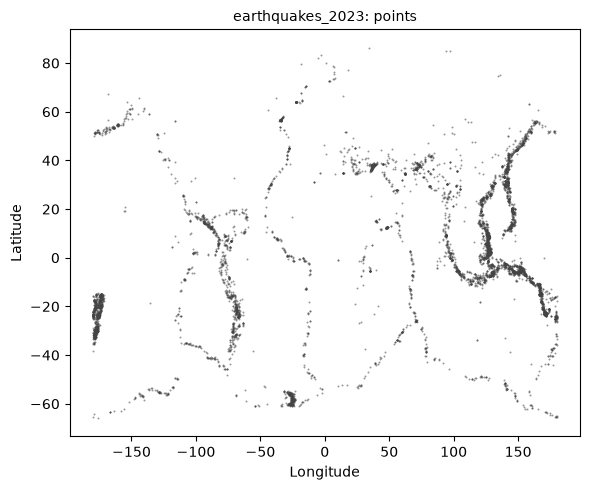

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/earthquakes_2023_data.png')

In [3]:
from sc4020.generate_figures import plot_coords, scatter_labels, show_and_save

x, y, x_label, y_label = plot_coords(ds)
fig, ax = plt.subplots(figsize=(6, 5))
scatter_labels(
    ax,
    np.column_stack([x, y]),
    ds.target,
    title=f"{DATASET_NAME}: {'classes' if ds.target is not None else 'points'}",
    class_names=ds.get("target_names"),
    size=2 if len(ds.data) > 5000 else 12,
)
ax.set_xlabel(x_label)
ax.set_ylabel(y_label)
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_data")

## 2. Clustering with K-Means

The number of clusters k comes from the fake-data check: for each k, the silhouette on the real data
minus the mean silhouette on copies with every column shuffled, among the k whose seeds agree. On
labelled data K-Means uses the true number of classes, and the label-free choice is shown next to it.
Plain K-Means starts from random centres; K-Means++ (next section) uses the same k.

In [4]:
selections, results = {}, {}
selections["K-Means"] = run.select_method(ds, "K-Means", k_range=k_range)
kmeans_tried = pd.DataFrame(selections["K-Means"].tried)
label_free_k = selections["K-Means"].label_free["n_clusters"]
print(f"k used: {selections['K-Means'].params['n_clusters']}, label-free choice: {label_free_k}")
kmeans_tried.round(3)

k used: 6, label-free choice: 6


,n_clusters,inertia,silhouette,null_silhouette,null_gap,davies_bouldin,smallest_cluster,largest_cluster,mean_seed_ari,min_seed_ari
0,2,3582.843,0.478,0.342,0.136,1.080,2109,5534,1.000,1.000
1,3,2432.297,0.434,0.345,0.089,0.817,1585,3907,1.000,1.000
2,4,1616.065,0.510,0.312,0.198,0.760,999,3466,1.000,1.000
3,5,1309.450,0.527,0.314,0.214,0.728,494,3433,0.941,0.708
4,6,1030.725,0.520,0.319,0.201,0.740,493,2368,0.990,0.974
5,8,746.355,0.524,0.319,0.205,0.720,268,2056,0.972,0.932
6,10,567.523,0.531,0.306,0.225,0.721,283,1966,0.940,0.712
7,15,308.112,0.567,0.310,0.257,0.623,99,1548,0.926,0.743
8,20,199.867,0.551,0.294,0.258,0.608,97,1045,0.885,0.754
9,30,116.662,0.564,0.277,0.287,0.596,42,979,0.928,0.827


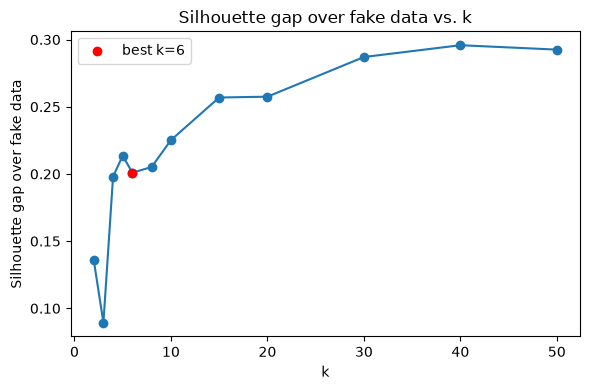

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/earthquakes_2023_kmeans_k_selection.png')

In [5]:
from sc4020.generate_figures import plot_k_selection, show_and_save

fig = plot_k_selection(
    kmeans_tried["n_clusters"].tolist(),
    kmeans_tried["null_gap"].tolist(),
    best_k=label_free_k,
    ylabel="Silhouette gap over fake data",
)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_kmeans_k_selection")

In [6]:
selections["K-Means (random init)"] = run.select_method(ds, "K-Means (random init)", selections)
results["K-Means (random init)"] = run.fit_method(
    ds, "K-Means (random init)", selections["K-Means (random init)"]
)

## 3. Clustering with K-Means++

In [7]:
results["K-Means"] = run.fit_method(ds, "K-Means", selections["K-Means"])
pd.DataFrame(
    {
        name: {
            "inertia": results[name].model.inertia_,
            "iterations": results[name].model.n_iter_,
            "fit_seconds": results[name].fit_seconds,
        }
        for name in ("K-Means (random init)", "K-Means")
    }
).T.round(3)

,inertia,iterations,fit_seconds
K-Means (random init),1033.984,13.0,0.023
K-Means,1030.725,6.0,0.026


## 4. Clustering with DBSCAN

min_samples follows the dimension, and eps is tried at multiples of the knee of the k-distance curve.
The rule keeps settings with at least 2 clusters and at most half the points as noise, then takes the
highest silhouette.

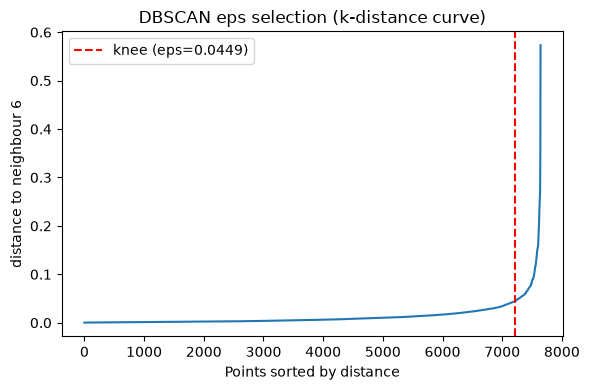

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/earthquakes_2023_dbscan_k_distance.png')

In [8]:
from sc4020.generate_figures import plot_k_distance, show_and_save

min_samples = tuning.min_samples_from_dimension(ds.data.shape[1])
curve = tuning.k_distance_curve(ds.data, min_samples)
knee_index, eps_at_knee = tuning.find_knee(curve)
fig = plot_k_distance(curve, knee_index, eps_at_knee, min_samples)
show_and_save(fig, TOPIC, f"{DATASET_NAME}_dbscan_k_distance")

In [9]:
selections["DBSCAN"] = run.select_method(ds, "DBSCAN", max_clusters=MAX_CLUSTERS)
results["DBSCAN"] = run.fit_method(ds, "DBSCAN", selections["DBSCAN"])
print(f"chosen: {run.format_params(selections['DBSCAN'].params)}, rule satisfied: {selections['DBSCAN'].valid}")
pd.DataFrame(selections["DBSCAN"].tried).round(3)

chosen: eps=0.0392, min_samples=12, rule satisfied: True


,eps,min_samples,eps_factor,n_clusters,noise_fraction,largest_cluster_share,silhouette,passes
0,0.013,3,0.50,306,0.113,0.122,0.316,True
1,0.019,3,0.75,232,0.063,0.142,0.140,True
2,0.025,3,1.00,167,0.042,0.356,-0.104,True
3,0.032,3,1.25,140,0.031,0.357,0.000,True
4,0.038,3,1.50,109,0.023,0.386,0.177,True
5,0.051,3,2.00,71,0.015,0.662,0.022,True
6,0.076,3,3.00,32,0.009,0.739,-0.120,True
7,0.102,3,4.00,17,0.005,0.767,-0.163,True
8,0.022,6,0.50,103,0.113,0.180,0.258,True
9,0.034,6,0.75,84,0.060,0.357,0.260,True


## 5. Clustering with HDBSCAN

In [10]:
selections["HDBSCAN"] = run.select_method(ds, "HDBSCAN", max_clusters=MAX_CLUSTERS)
results["HDBSCAN"] = run.fit_method(ds, "HDBSCAN", selections["HDBSCAN"])
print(f"chosen: {run.format_params(selections['HDBSCAN'].params)}, rule satisfied: {selections['HDBSCAN'].valid}")
pd.DataFrame(selections["HDBSCAN"].tried).round(3)

chosen: min_cluster_size=50, min_samples=None, rule satisfied: True


,min_cluster_size,min_samples,n_clusters,noise_fraction,largest_cluster_share,silhouette,passes
0,5,NaN,343,0.233,0.061,0.591,True
1,5,5.0,343,0.233,0.061,0.591,True
2,5,10.0,175,0.282,0.066,0.690,True
3,10,NaN,143,0.268,0.073,0.704,True
4,10,5.0,182,0.208,0.069,0.625,True
5,10,10.0,143,0.268,0.073,0.704,True
6,15,NaN,101,0.279,0.072,0.717,True
7,15,5.0,138,0.221,0.073,0.651,True
8,15,10.0,110,0.231,0.073,0.687,True
9,20,NaN,75,0.295,0.072,0.717,True


## 6. Clustering with GMM

The number of components and the covariance type with the lowest BIC (the number of components is the
number of classes on labelled data).

In [11]:
selections["GMM"] = run.select_method(ds, "GMM", k_range=k_range)
results["GMM"] = run.fit_method(ds, "GMM", selections["GMM"])
gmm_tried = pd.DataFrame(selections["GMM"].tried).rename(columns={"score": "minus_bic"})
print(f"chosen: {run.format_params(selections['GMM'].params)}, label-free: {run.format_params(selections['GMM'].label_free)}")
gmm_tried.pivot(index="n_components", columns="covariance_type", values="minus_bic").round(1)

chosen: n_components=50, covariance_type=full, label-free: n_components=50, covariance_type=full


covariance_type,diag,full,spherical,tied
n_components,,,,
2,-25703.6,-17103.1,-27450.8,-25036.0
3,-12297.2,-3358.3,-16487.4,-22148.6
4,-10773.9,1883.3,-14680.2,-18210.7
5,-5820.2,7769.7,-10633.8,-16959.6
6,-5190.0,9505.8,-7657.5,-14993.4
8,5987.8,16549.8,-6355.0,-11541.6
10,11053.3,23738.6,590.4,-9448.2
15,16700.6,36330.3,6367.6,-2257.4
20,24689.4,44946.7,17832.3,3045.1


## 7. Clustering with Spectral

Spectral clustering at the K-Means k: an RBF affinity on Wine, a 10-nearest-neighbour graph elsewhere
(`run.SPECTRAL_AFFINITY_BY_DATASET`). A dense RBF affinity needs memory quadratic in the number of
points, so it is skipped on large data; the nearest-neighbour graph is sparse and runs at any size.

In [12]:
if run.is_too_large(ds, "Spectral"):
    print(f"skipping Spectral: {len(ds.data):,} points is above {run.MAX_POINTS_FOR_DENSE_SPECTRAL:,}")
else:
    selections["Spectral"] = run.select_method(ds, "Spectral", selections)
    results["Spectral"] = run.fit_method(ds, "Spectral", selections["Spectral"])
    print(f"Spectral: {run.format_params(selections['Spectral'].params)}")

Spectral: n_clusters=6, affinity=nearest_neighbors


## 8. Metrics

Internal scores (silhouette, Davies-Bouldin, DBCV) need no labels; ARI and NMI compare with the classes
when there are any. Noise points are left out of the internal scores. The null columns refit each
method at its setting on a copy with every column shuffled: a silhouette near the null one means the
clusters are no stronger than on data without structure.

In [13]:
table = run.score_methods(ds, selections, results)
run.save_dataset_run(DATASET_NAME, table, run.tried_settings(ds, selections))
columns = [
    "method",
    "params",
    "n_clusters",
    "noise_fraction",
    "largest_cluster_share",
    "silhouette",
    "davies_bouldin",
    "dbcv",
    "ari",
    "nmi",
    "fit_seconds",
    "null_silhouette",
]
table[[column for column in columns if column in table]].round(3)

,method,params,n_clusters,noise_fraction,largest_cluster_share,silhouette,davies_bouldin,dbcv,fit_seconds,null_silhouette
0,K-Means (random init),n_clusters=6,6,0.000,0.313,0.512,0.728,-0.869,0.023,0.320
1,K-Means,n_clusters=6,6,0.000,0.310,0.516,0.740,-0.821,0.026,0.319
2,DBSCAN,"eps=0.0392, min_samples=12",42,0.113,0.357,0.420,0.374,-0.031,0.034,0.599
3,HDBSCAN,"min_cluster_size=50, min_samples=None",28,0.307,0.075,0.756,0.329,0.435,0.232,0.317
4,GMM,"n_components=50, covariance_type=full",50,0.000,0.073,0.554,0.631,-0.219,1.934,-0.135
5,Spectral,"n_clusters=6, affinity=nearest_neighbors",6,0.000,0.316,0.334,0.914,-0.879,0.118,0.295


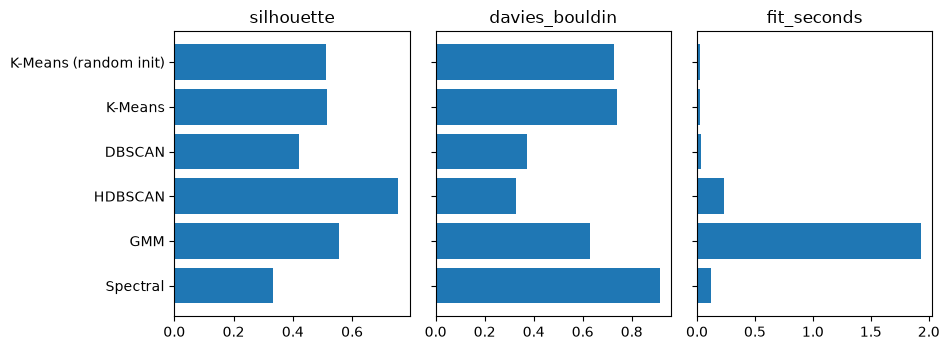

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/earthquakes_2023_metrics.png')

In [14]:
from sc4020.generate_figures import show_and_save

metric_names = [m for m in ("silhouette", "davies_bouldin", "ari", "fit_seconds") if m in table]
fig, axes = plt.subplots(1, len(metric_names), figsize=(3.2 * len(metric_names), 3.6), sharey=True)
for ax, metric in zip(axes, metric_names):
    ax.barh(table["method"], table[metric])
    ax.set_title(metric)
axes[0].invert_yaxis()
fig.tight_layout()
show_and_save(fig, TOPIC, f"{DATASET_NAME}_metrics")

## 9. Visualization

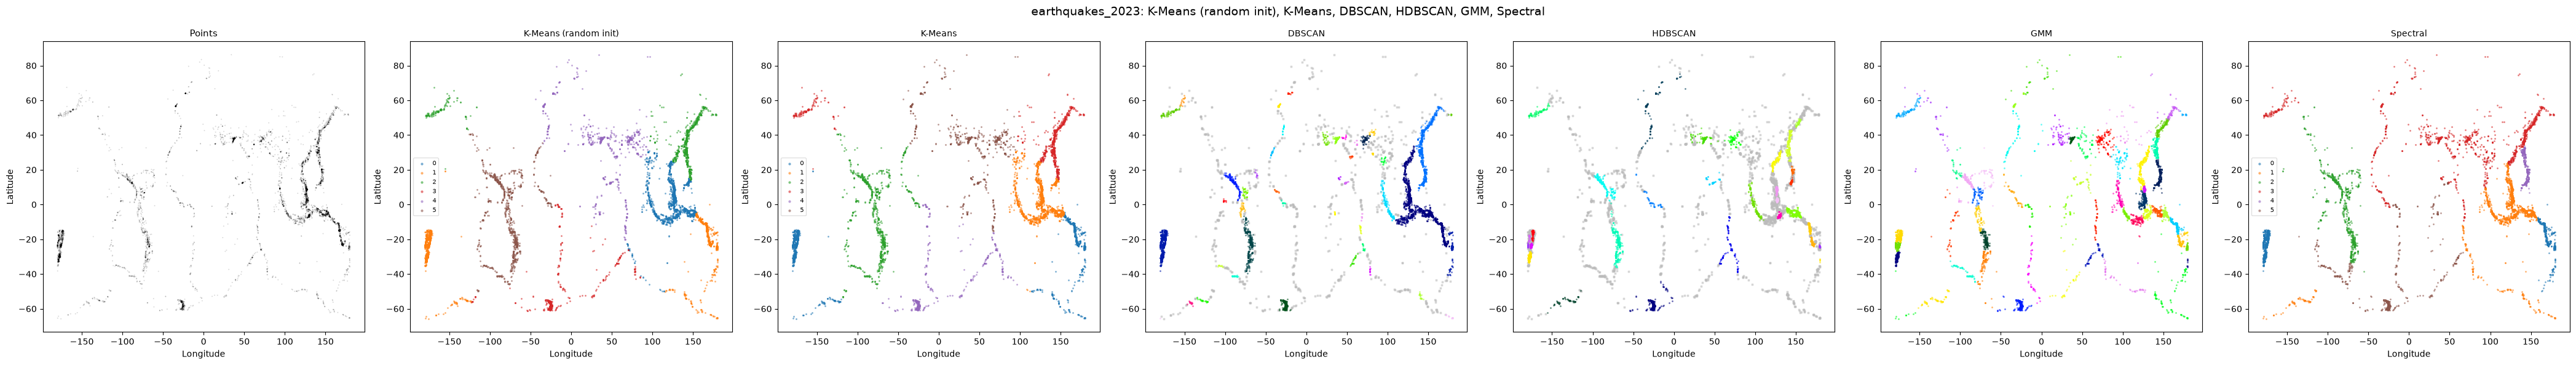

PosixPath('/home/duonghoangvulam/projects/sc4020/.claude/worktrees/combine-src/results/datasets/figures/earthquakes_2023_clusters.png')

In [15]:
from sc4020.generate_figures import show_and_save

fig = run.plot_dataset(ds, results, table, title=f"{DATASET_NAME}: {', '.join(results)}")
show_and_save(fig, TOPIC, f"{DATASET_NAME}_clusters")